# 03 Encoder

Phase 3 walkthrough: a small neural network that turns a player-season's 15 style z-scores into a short embedding, trained so that different seasons of the same player land close together. Stage A pretrains it to fill in hidden stats (25% of each row is swapped for values from other rows); Stage B trains it contrastively on pairs of seasons from the same player, preferring seasons at least 2 years apart. The inputs are the same 15 z-scores as the Phase 2 baselines, so the comparison is fair.

The bar to beat is **B2 cosine** (non-adjacent hit@10 0.668, next-season RMSE 0.608, persistence 0.610, sanity mean 1.70 of 5).

This notebook **only reads**. It trains nothing and writes nothing under `reports/` or `models/`: it loads `reports/phase3_search.csv` and the saved weights of the chosen setting. Numbers are on the **validation** split, which also chose the setting and the early-stopping epoch, so the encoder's numbers are optimistic. The test split and the five hold-outs are never touched. The sanity comps in section 5 are shown but not yet marked or scored.

In [1]:
import json, sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from sklearn.decomposition import PCA

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

from baselines import B2Cosine
from evaluate import SANITY, comp_players, era_and_position, next_season, retrieval
from evaluate_encoder import MODELS, SEARCH_CSV, SEEDS, load_encoder, splits, stability

pd.set_option("display.width", 160)
pd.set_option("display.max_colwidth", 120)
df, train, val, trval, pool = splits()
search = pd.read_csv(SEARCH_CSV)
report_text = (ROOT / "reports" / "phase3_encoder.md").read_text()
B2_NONADJ, B2_RMSE, PERSISTENCE = 0.668, 0.608, 0.610

# the chosen setting: best mean validation non-adjacent hit@10 over 3 seeds (ties: lower next-season RMSE)
agg = (search.groupby(["dim", "temperature", "pretraining"])
       .agg(nonadj=("nonadj_hit10", "mean"), next_rmse=("next_rmse", "mean")).reset_index()
       .sort_values(["nonadj", "next_rmse"], ascending=[False, True]).reset_index(drop=True))
best = agg.iloc[0]
setting = (int(best["dim"]), float(best["temperature"]), bool(best["pretraining"]))
print(f"{len(search)} search runs. Chosen setting: embedding size {setting[0]}, temperature {setting[1]}, "
      f"pretraining {'yes' if setting[2] else 'no'}")

54 search runs. Chosen setting: embedding size 32, temperature 0.05, pretraining yes


## 1. Training curves

The saved checkpoint of the chosen setting (seed 2026) keeps its per-epoch history. Stage A's validation error on the hidden stats should sit well below the "predict 0" line (predict the season mean). Stage B stops when validation non-adjacent hit@10 has not improved for 10 epochs and keeps the best epoch's weights.

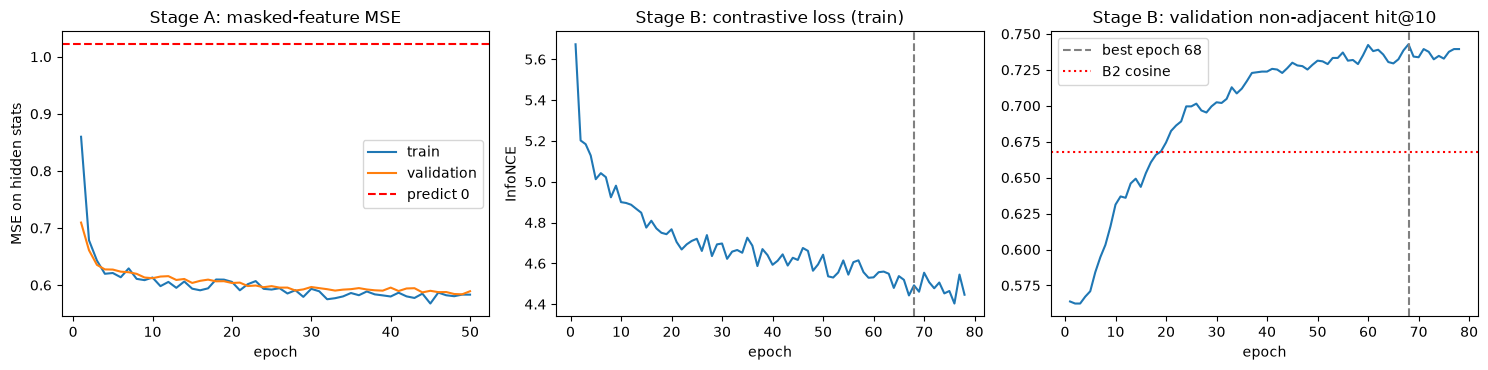

Stage A validation MSE 0.589 vs predicting 0: 1.022
Stage B ran 78 epochs; best validation non-adjacent hit@10 0.743 at epoch 68


In [2]:
ckpt = torch.load(MODELS / f"d{setting[0]}_t{setting[1]}_{'pre' if setting[2] else 'nopre'}_s2026.pt", weights_only=False)
hist = ckpt["history"]
con = pd.DataFrame(hist["contrastive"])
best_epoch = int(con.loc[con["val_nonadj_hit10"].idxmax(), "epoch"])

ncols = 3 if "pretrain" in hist else 2
fig, axes = plt.subplots(1, ncols, figsize=(5 * ncols, 3.8))
i = 0
if "pretrain" in hist:
    pre = pd.DataFrame(hist["pretrain"])
    axes[0].plot(pre["epoch"], pre["train"], label="train")
    axes[0].plot(pre["epoch"], pre["val"], label="validation")
    axes[0].axhline(pre["predict_0"].iloc[0], c="red", ls="--", label="predict 0")
    axes[0].set(title="Stage A: masked-feature MSE", xlabel="epoch", ylabel="MSE on hidden stats"); axes[0].legend()
    i = 1
axes[i].plot(con["epoch"], con["loss"]); axes[i].axvline(best_epoch, c="grey", ls="--")
axes[i].set(title="Stage B: contrastive loss (train)", xlabel="epoch", ylabel="InfoNCE")
axes[i + 1].plot(con["epoch"], con["val_nonadj_hit10"]); axes[i + 1].axvline(best_epoch, c="grey", ls="--", label=f"best epoch {best_epoch}")
axes[i + 1].axhline(B2_NONADJ, c="red", ls=":", label="B2 cosine")
axes[i + 1].set(title="Stage B: validation non-adjacent hit@10", xlabel="epoch"); axes[i + 1].legend()
plt.tight_layout(); plt.show()
if "pretrain" in hist:
    print(f"Stage A validation MSE {pre['val'].iloc[-1]:.3f} vs predicting 0: {pre['predict_0'].iloc[0]:.3f}")
print(f"Stage B ran {len(con)} epochs; best validation non-adjacent hit@10 {con['val_nonadj_hit10'].max():.3f} at epoch {best_epoch}")

## 2. The search

18 settings (embedding size x temperature x pretraining), each trained with 3 seeds: 54 runs, fixed in advance. Bars are the mean over seeds. The red line is B2 cosine; on the RMSE panels the dashed grey line is persistence (predict next season = this season).

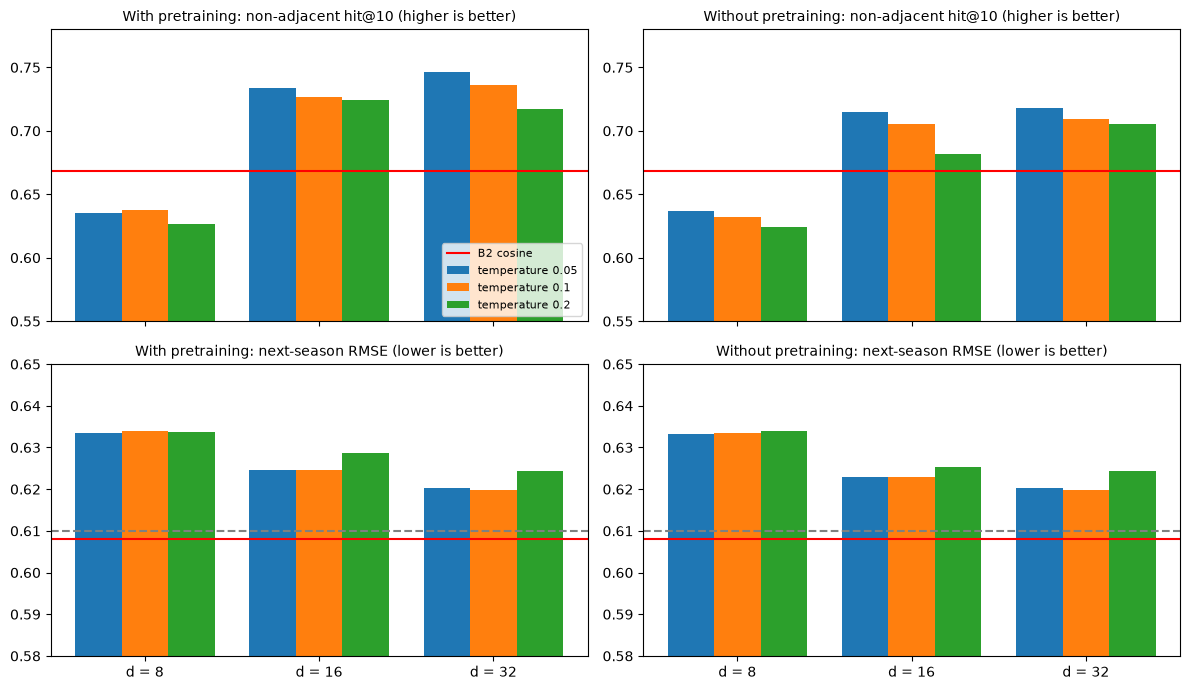

,nonadj_hit10,next_rmse
dim,,
8,0.632,0.634
16,0.714,0.625
32,0.722,0.622


pretraining,no pretraining,pretraining
dim,,
8,0.631,0.633
16,0.700,0.728
32,0.711,0.733


Runs beating B2 on non-adjacent hit@10 (0.668): 36 of 54
Runs beating B2 on next-season RMSE (0.608): 0 of 54; best single run 0.617


In [3]:
fig, axes = plt.subplots(2, 2, figsize=(12, 7), sharex=True)
temps = sorted(search["temperature"].unique())
dims = sorted(search["dim"].unique())
for col, pre in enumerate([True, False]):
    sub = search[search["pretraining"] == pre].groupby(["dim", "temperature"]).mean(numeric_only=True)
    for row, (metric, ref, lab) in enumerate([("nonadj_hit10", B2_NONADJ, "non-adjacent hit@10 (higher is better)"),
                                              ("next_rmse", B2_RMSE, "next-season RMSE (lower is better)")]):
        ax = axes[row, col]
        w = 0.8 / len(temps)
        for k, t in enumerate(temps):
            ax.bar(np.arange(len(dims)) + k * w, [sub.loc[(d, t), metric] for d in dims], w, label=f"temperature {t}")
        ax.axhline(ref, c="red", label="B2 cosine")
        if metric == "next_rmse":
            ax.axhline(PERSISTENCE, c="grey", ls="--", label="persistence")
            ax.set_ylim(0.58, 0.65)
        else:
            ax.set_ylim(0.55, 0.78)
        ax.set_xticks(np.arange(len(dims)) + w, [f"d = {d}" for d in dims])
        ax.set_title(f"{'With' if pre else 'Without'} pretraining: {lab}", fontsize=10)
axes[0, 0].legend(fontsize=8, loc="lower right")
plt.tight_layout(); plt.show()

by_dim = search.groupby("dim")[["nonadj_hit10", "next_rmse"]].mean().round(3)
by_pre = search.groupby(["dim", "pretraining"])["nonadj_hit10"].mean().unstack().round(3)
display(by_dim)
display(by_pre.rename(columns={False: "no pretraining", True: "pretraining"}))
print(f"Runs beating B2 on non-adjacent hit@10 ({B2_NONADJ}): {(search['nonadj_hit10'] > B2_NONADJ).sum()} of {len(search)}")
print(f"Runs beating B2 on next-season RMSE ({B2_RMSE}): {(search['next_rmse'] < B2_RMSE).sum()} of {len(search)}; "
      f"best single run {search['next_rmse'].min():.3f}")

## 3. Encoder vs B2

The three seed models of the chosen setting are loaded from disk (nothing is retrained) and scored with the same Phase 2 functions as B2. The last line checks the numbers against `reports/phase3_encoder.md`.

,encoder (mean),encoder (sd over seeds),B2 cosine
hit@10,0.857,0.004,0.778
MRR,0.646,0.003,0.561
non-adjacent hit@10,0.746,0.006,0.668
next-season RMSE,0.620,0.003,0.608
stability ratio,0.165,0.001,0.243


Persistence RMSE 0.610; encoder next-season RMSE vs persistence: +1.7%


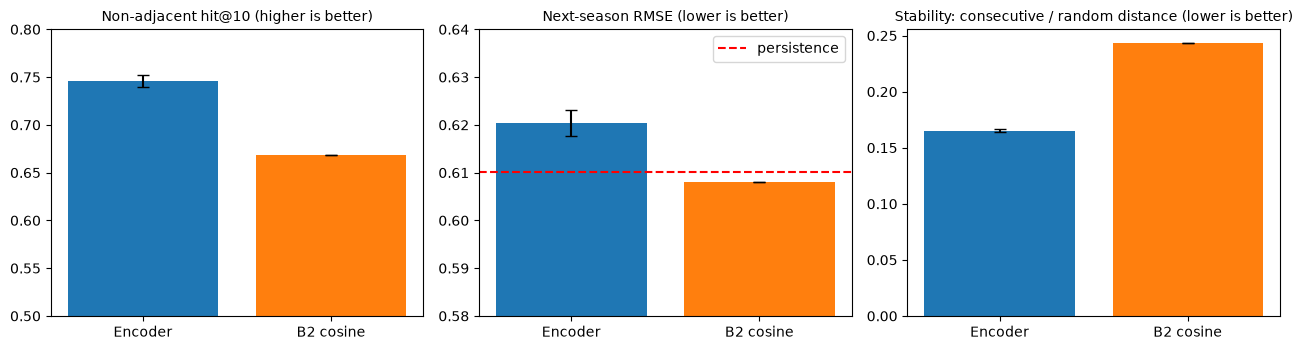

Matches reports/phase3_encoder.md


In [4]:
encs = [load_encoder(*setting, s) for s in SEEDS]
b2 = B2Cosine().fit(train)

def scores(m):
    ret, na, ns, st = retrieval(m, val), retrieval(m, val, non_adjacent=True), next_season(m, val), stability(m, val)
    return {"hit@10": ret["hit10"], "MRR": ret["mrr"], "non-adjacent hit@10": na["hit10"], "next-season RMSE": ns["rmse"],
            "stability ratio": st["ratio"], "persistence": ns["persistence"]}

seed_tab = pd.DataFrame([scores(e) for e in encs], index=SEEDS)
b2_tab = scores(b2)
cmp = pd.DataFrame({"encoder (mean)": seed_tab.mean(), "encoder (sd over seeds)": seed_tab.std(), "B2 cosine": pd.Series(b2_tab)})
display(cmp.drop("persistence").round(3))
print(f"Persistence RMSE {b2_tab['persistence']:.3f}; encoder next-season RMSE vs persistence: "
      f"{(seed_tab['next-season RMSE'].mean() - b2_tab['persistence']) / b2_tab['persistence']:+.1%}")

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
for ax, k, title in zip(axes, ["non-adjacent hit@10", "next-season RMSE", "stability ratio"],
                        ["Non-adjacent hit@10 (higher is better)", "Next-season RMSE (lower is better)",
                         "Stability: consecutive / random distance (lower is better)"]):
    ax.bar(["Encoder", "B2 cosine"], [seed_tab[k].mean(), b2_tab[k]], yerr=[seed_tab[k].std(), 0], capsize=4, color=["tab:blue", "tab:orange"])
    ax.set_title(title, fontsize=10)
    if k == "next-season RMSE":
        ax.axhline(b2_tab["persistence"], c="red", ls="--", label="persistence"); ax.set_ylim(0.58, 0.64); ax.legend()
    if k == "non-adjacent hit@10":
        ax.set_ylim(0.5, 0.8)
plt.tight_layout(); plt.show()

# must match the saved report
m, sd = seed_tab.mean(), seed_tab.std()
for label, k in [("Hit@10", "hit@10"), ("MRR", "MRR"), ("Non-adjacent hit@10", "non-adjacent hit@10"), ("Next-season RMSE", "next-season RMSE")]:
    line = f"| {label} | {m[k]:.3f} ± {sd[k]:.3f} | {b2_tab[k]:.3f} |"
    assert line in report_text, f"notebook and report disagree: {line}"
print("Matches reports/phase3_encoder.md")

## 4. What the embedding looks like

The seed 2026 embedding of every validation season, projected to 2 dimensions with PCA. A 2D picture throws most of the embedding away, so it is for intuition only (feature note, check 6). Left: coloured by primary listed position. Right: coloured by decade.

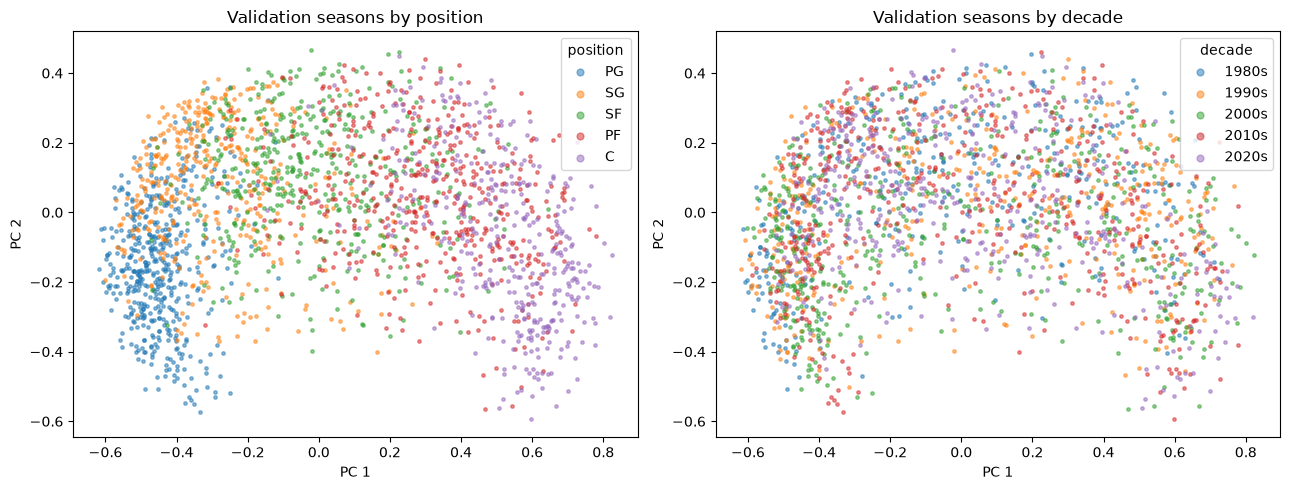

Probes (balanced accuracy, chance 0.20):  era: encoder 0.323, B2 cosine 0.190;  position: encoder 0.656, B2 cosine 0.661


In [5]:
emb = encs[0].embed(val)
xy = PCA(n_components=2, random_state=0).fit_transform(emb)
pos = val["pos"].astype(str).str.split("-").str[0]
decade = (np.minimum((val["season"] // 10) * 10, 2020)).astype(int)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for p in ["PG", "SG", "SF", "PF", "C"]:
    k = (pos == p).to_numpy()
    axes[0].scatter(xy[k, 0], xy[k, 1], s=6, alpha=0.5, label=p)
axes[0].legend(markerscale=2, title="position"); axes[0].set_title("Validation seasons by position")
for d in sorted(decade.unique()):
    k = (decade == d).to_numpy()
    axes[1].scatter(xy[k, 0], xy[k, 1], s=6, alpha=0.5, label=f"{d}s")
axes[1].legend(markerscale=2, title="decade"); axes[1].set_title("Validation seasons by decade")
for ax in axes:
    ax.set(xlabel="PC 1", ylabel="PC 2")
plt.tight_layout(); plt.show()
probes_enc = pd.DataFrame([era_and_position(e, trval) for e in encs]).mean()
probes_b2 = era_and_position(b2, trval)
print(f"Probes (balanced accuracy, chance 0.20):  era: encoder {probes_enc['era']:.3f}, B2 cosine {probes_b2['era']:.3f};  "
      f"position: encoder {probes_enc['position']:.3f}, B2 cosine {probes_b2['position']:.3f}")

## 5. Comps side by side

Top 5 comp players (each counted once, best-matching season; hold-outs excluded from the pool) for four players. These comps are **not yet marked or scored**: marking waits for Danny.

In [6]:
by_name = {v: k for k, v in SANITY.items()}
rows = []
for name in ["Michael Jordan", "Steve Nash", "Dennis Rodman", "Nikola Jokić"]:
    q = df[df["player_id"] == by_name[name]]
    for label, model in [("Encoder", encs[0]), ("B2 cosine", b2)]:
        c = comp_players(model, q, pool, n=5)
        rows.append({"player": name, "model": label, "top 5": ", ".join(f"{p} {s}" for p, s in zip(c["player"], c["season"]))})
pd.DataFrame(rows).set_index(["player", "model"])

top 5
player         model                                                                                                             
Michael Jordan Encoder                 Kobe Bryant 2003, LeBron James 2012, Tracy McGrady 2005, Dwyane Wade 2006, Grant Hill 1999
               B2 cosine           Kobe Bryant 2000, George Gervin 1981, Tracy McGrady 2006, Kawhi Leonard 2026, Dwyane Wade 2012
Steve Nash     Encoder         Jordan Farmar 2012, Kirk Hinrich 2004, Steve Blake 2008, Anthony Goldwire 1997, Jameer Nelson 2009
               B2 cosine             Jordan Farmar 2012, Mark Price 1993, José Calderón 2009, Kenny Smith 1991, Jarrett Jack 2010
Dennis Rodman  Encoder                 Larry Smith 1982, Jeff Foster 2005, Reggie Evans 2011, Michael Cage 1990, Jamie Feick 1999
               B2 cosine       Jeff Foster 2004, Charles Oakley 1990, Larry Micheaux 1985, Trevor Booker 2015, Nazr Mohammed 2008
Nikola Jokić   Encoder    Kevin Garnett 2005, Arvydas Sabonis 1996, Greg Monroe 2012, Domantas Sabonis 2021, Charles Barkley 1996
               B2 cosine        Alvan Adams 1981, Kevin Garnett 2005, LeBron James 2013, Domantas Sabonis 2021, Gorgui Dieng 2019

## 6. Findings

- **Retrieval:** the chosen encoder (embedding size 32, temperature 0.05, pretraining) beats B2 cosine on every retrieval metric in section 3: non-adjacent hit@10 0.746 against 0.668, hit@10 0.857 against 0.778. 36 of the 54 search runs beat B2's 0.668.
- **Next-season error:** the encoder is worse than B2 (0.620 against 0.608) and worse than persistence (0.610). No single one of the 54 runs gets below 0.608 or 0.610; the best is 0.617.
- **Size matters most:** mean non-adjacent hit@10 is 0.632 at embedding size 8, 0.714 at 16 and 0.722 at 32. No size-8 run beats B2 on non-adjacent retrieval.
- **Pretraining helps a little, and only above size 8:** it adds about 0.02 to 0.03 non-adjacent hit@10 at sizes 16 and 32 and nothing at size 8 (0.633 against 0.631).
- **Stability:** consecutive seasons of the same player are much closer than random pairs (ratio about 0.17 for the encoder against 0.24 for B2).
- **Era:** the era probe reads about 0.32 for the encoder against 0.19 for B2, both against 0.20 chance. The encoder's embedding carries more decade information than B2's.
- **Position** is well above chance for both models (about 0.66, section 4).
- **Caveat:** these are validation numbers that also picked the setting, so they are optimistic. The sanity comps are unmarked, so there is no sanity verdict yet.